# 1 · Wheel movements as sums of primitives

*Part A: the method, tested on two sessions. Part B: more example decompositions (was `1b_primitives_examples`).*

## Part A · test on two sessions

**Idea.** A reaching or turning movement is not one smooth push: its velocity profile often has several bumps (a main push, then corrections). The motor-control literature models each bump as a stereotyped *primitive* (a *sub-movement*) and the movement as their sum. Every primitive has a start time, a duration and a signed size (displacement). Fitting this turns a continuous trace into a short, discrete sequence of units: the candidate "chunks" for modelling learning.

**Two standard primitive shapes**
- **Minimum-jerk** (Flash & Hogan 1985): the smoothest point-to-point movement; symmetric bell-shaped velocity of fixed duration T, `v(t) = D/T · (30τ² − 60τ³ + 30τ⁴)`, τ = (t − t0)/T.
- **Lognormal** (Plamondon's kinematic theory, 1995; "sigma-lognormal" model): skewed velocity, fast rise and slow decay, as produced by a chain of many neuromuscular sub-systems; parameters t0, μ, σ, D.

**Fitting.** Rohrer & Hogan (2003, *Biol Cybern*, "Avoiding spurious submovement decompositions") showed that local fits find many spurious solutions and gave a globally optimal branch-and-bound method. Here a cheaper greedy version: add a primitive at the largest residual lobe, refit all jointly, stop at 95 % of velocity energy explained (`primitives.py`). Classic applications: Novak, Miller & Houk (2002) on rapid aimed movements; stroke recovery, where primitives become fewer, larger and more overlapping with practice (Rohrer et al. 2002, *J Neurosci*, "Movement smoothness changes during stroke recovery").

**Movements** are IBL's own: `alf/_ibl_wheelMoves.intervals` (the detector behind `firstMovement_times`). Velocity: our 200 Hz design matrices (20 Hz low-pass → primitives shorter than ~80 ms are not resolvable).

Test: CSHL049, first (1) and last (15) training session.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from joblib import Parallel, delayed
from one.api import ONE
import wheel_states as ws, primitives as pr

one = ONE(mode='remote')
MOUSE = 'CSHL049'
man = ws.manifest().query('mouse == @MOUSE').sort_values('session_index')
SESS = {int(r.session_index): r.eid for _, r in man.iloc[[0, -1]].iterrows()}
GREY, BLACK = '0.6', 'k'                    # first, last session
EPOCHS = ['pre-stim', 'response', 'post-feedback']
EPOCH_C = {'pre-stim': 'tab:blue', 'response': 'tab:orange', 'post-feedback': 'tab:green'}

## Movements and their trial epoch

In [2]:
def epoch_of(on, tr):
    """pre-stim: trial start -> stimulus (quiescence, where moving restarts the timer);
    response: stimulus -> feedback; post-feedback: feedback -> next trial start."""
    i = np.searchsorted(tr.intervals_0.values, on, side='right') - 1
    if i < 0:
        return 'post-feedback', -1
    r = tr.iloc[i]
    if on < r.stimOn_times:
        return 'pre-stim', i
    if on <= r.feedback_times:
        return 'response', i
    return 'post-feedback', i

S = {}
for k, eid in SESS.items():
    dm, tr = ws.load_session(eid, MOUSE)
    wm = one.load_object(eid, 'wheelMoves', collection='alf')
    mv = pd.DataFrame(wm['intervals'], columns=['onset', 'offset'])
    ep = [epoch_of(o, tr) for o in mv.onset]
    mv['epoch'] = [e for e, _ in ep]; mv['trial'] = np.array([i for _, i in ep], int)
    mv['duration'] = mv.offset - mv.onset
    i0, i1 = np.searchsorted(dm.times.values, [mv.onset, mv.offset]).astype(int)
    mv['displacement'] = dm.position.values[np.minimum(i1, len(dm) - 1)] - dm.position.values[i0]
    S[k] = dict(dm=dm, tr=tr, mv=mv)
    print(f'session {k}: {len(mv)} movements, {len(tr)} trials;',
          mv.epoch.value_counts().to_dict())

session 1: 637 movements, 203 trials; {'response': 352, 'pre-stim': 179, 'post-feedback': 106}


session 15: 1952 movements, 826 trials; {'response': 813, 'post-feedback': 684, 'pre-stim': 455}


In [3]:
# which displacement sign is which choice? (last movement of the response epoch vs the trial's choice)
for k, s in S.items():
    resp = s['mv'].query('epoch == "response"').groupby('trial').last()
    ch = s['tr'].choice.values[resp.index]
    print(f'session {k}:', pd.crosstab(np.sign(resp.displacement), ch, rownames=['sign(D)'], colnames=['choice']).to_dict())

session 1: {-1.0: {-1.0: 4, 1.0: 67}, 0.0: {-1.0: 2, 1.0: 1}, 1.0: {-1.0: 121, 1.0: 1}}
session 15: {-1.0: {-1.0: 2, 1.0: 250}, 0.0: {-1.0: 1, 1.0: 0}, 1.0: {-1.0: 416, 1.0: 84}}


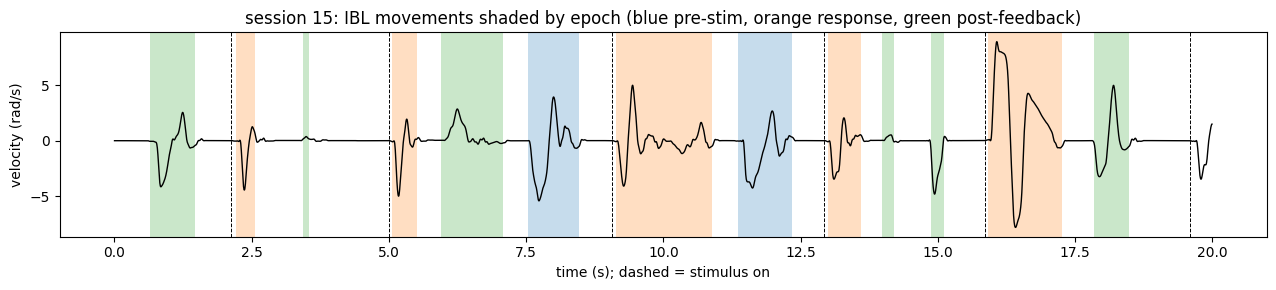

In [4]:
k = max(S); s = S[k]
t0 = s['tr'].stimOn_times.iloc[200] - 5
sel = (s['dm'].times > t0) & (s['dm'].times < t0 + 20)
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(s['dm'].times[sel] - t0, s['dm'].velocity[sel], c=BLACK, lw=1)
for _, m in s['mv'].query('onset > @t0 and offset < @t0 + 20').iterrows():
    ax.axvspan(m.onset - t0, m.offset - t0, color=EPOCH_C[m.epoch], alpha=.25, lw=0)
for e in s['tr'].stimOn_times.values:
    if 0 < e - t0 < 20: ax.axvline(e - t0, c='k', ls='--', lw=.7)
ax.set(xlabel='time (s); dashed = stimulus on', ylabel='velocity (rad/s)',
       title=f'session {k}: IBL movements shaded by epoch (blue pre-stim, orange response, green post-feedback)')
plt.tight_layout()

## Fit every movement with both primitive shapes

In [5]:
def fit_one(kind, t, v, on, off):
    tt, vv = pr.movement_window(t, v, on, off)
    p, r2 = pr.fit_movement(kind, tt, vv)
    return p, r2

FITS = {}
for k, s in S.items():
    t, v = s['dm'].times.values, s['dm'].velocity.values.astype(float)
    for kind in pr.KINDS:
        FITS[k, kind] = Parallel(n_jobs=8)(delayed(fit_one)(kind, t, v, on, off)
                                           for on, off in zip(s['mv'].onset, s['mv'].offset))
        s['mv'][f'n_{kind}'] = [len(r2) for _, r2 in FITS[k, kind]]
        s['mv'][f'r2_{kind}'] = [r2[-1] for _, r2 in FITS[k, kind]]
pd.concat({k: s['mv'][[c for c in s['mv'] if c.startswith(('n_', 'r2_'))]].describe().loc[['mean', '50%', 'max']]
           for k, s in S.items()}).round(2)

n_minjerk  r2_minjerk  n_lognormal  r2_lognormal
1  mean       3.96        0.97         3.88          0.97
   50%        3.00        0.97         3.00          0.97
   max       15.00        1.00        15.00          1.00
15 mean       2.65        0.98         2.58          0.98
   50%        2.00        0.98         2.00          0.98
   max       15.00        1.00        15.00          1.00

### Example movements (last session), minimum-jerk vs lognormal

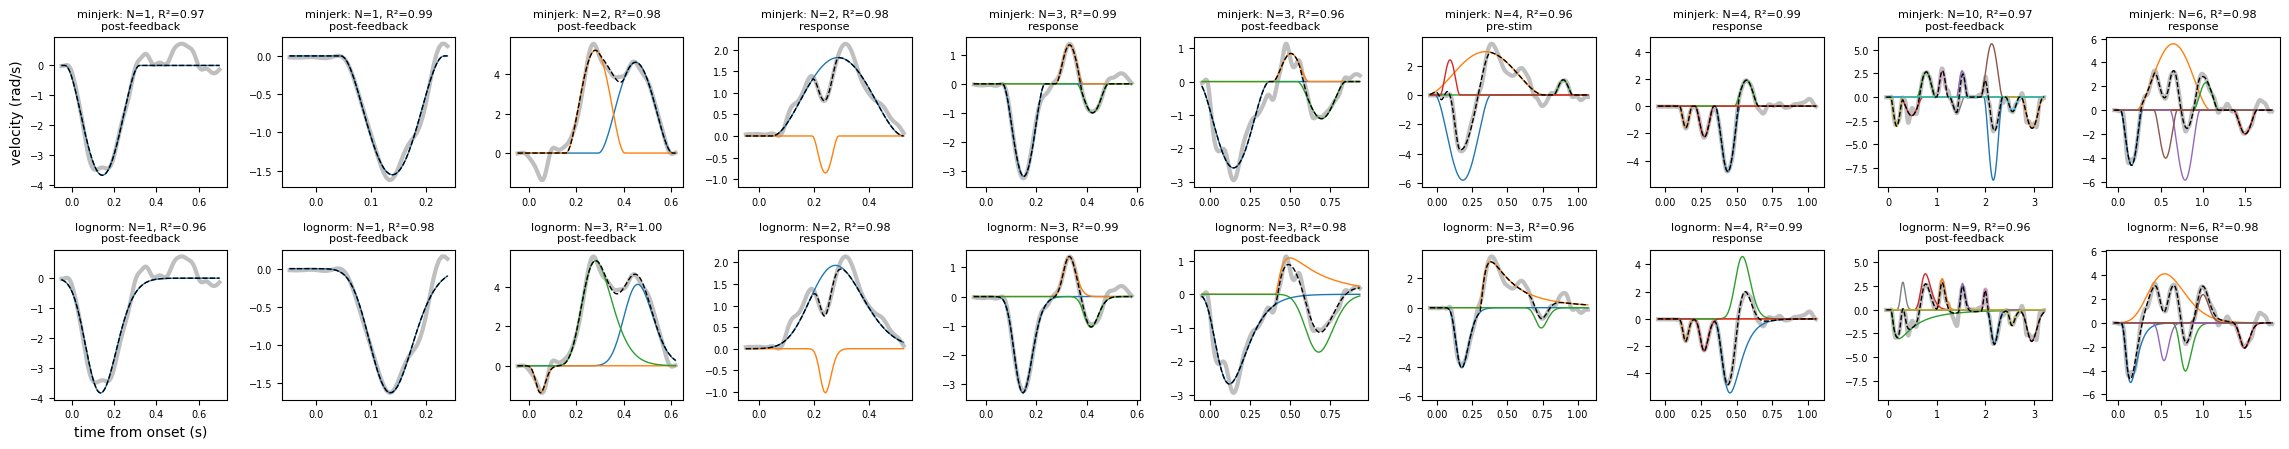

In [6]:
k = max(S); s = S[k]; mv = s['mv']
t, v = s['dm'].times.values, s['dm'].velocity.values.astype(float)
rng = np.random.default_rng(1)
pick = []
for n in [1, 2, 3, 4, 6]:
    idx = mv.index[(mv.n_minjerk == n) if n < 6 else (mv.n_minjerk >= n)]
    pick += list(rng.choice(idx, min(2, len(idx)), replace=False))
fig, axs = plt.subplots(2, len(pick), figsize=(2.3 * len(pick), 4.6), sharey='col')
for j, i in enumerate(pick):
    tt, vv = pr.movement_window(t, v, mv.onset[i], mv.offset[i])
    for row, kind in enumerate(pr.KINDS):
        p, r2 = FITS[k, kind][i]
        ax = axs[row, j]
        ax.plot(tt, vv, c='0.75', lw=3)
        for c in pr.components(kind, tt, p): ax.plot(tt, c, lw=1)
        ax.plot(tt, pr.model(kind, tt, p), c='k', lw=1, ls='--')
        ax.set_title(f'{kind[:7]}: N={len(r2)}, R²={r2[-1]:.2f}\n{mv.epoch[i]}', fontsize=8)
        ax.tick_params(labelsize=7)
axs[1, 0].set_xlabel('time from onset (s)'); axs[0, 0].set_ylabel('velocity (rad/s)')
plt.tight_layout()

### Which shape is more parsimonious? Primitives needed to reach 95 %

{1: (np.float64(3.96), np.float64(3.88)), 15: (np.float64(2.65), np.float64(2.58))} (mean N: minjerk, lognormal)


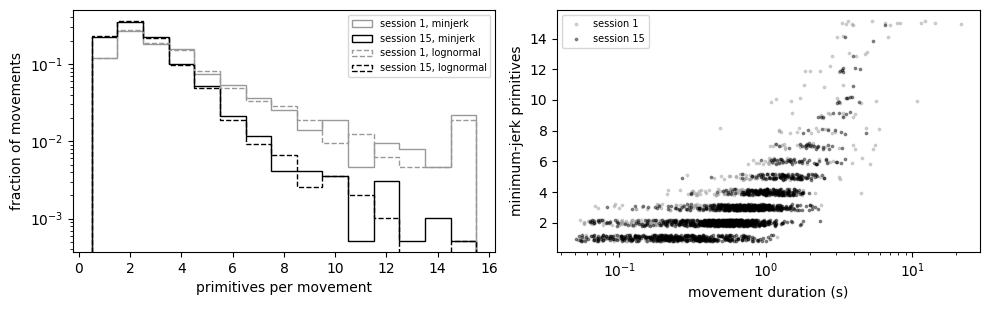

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
bins = np.arange(.5, pr.N_MAX + 1.5)
for kind, ls in zip(pr.KINDS, ['-', '--']):
    for k, c in zip(S, [GREY, BLACK]):
        axs[0].hist(S[k]['mv'][f'n_{kind}'], bins, histtype='step', color=c, ls=ls, density=True,
                    label=f'session {k}, {kind}')
axs[0].set(xlabel='primitives per movement', ylabel='fraction of movements', yscale='log'); axs[0].legend(fontsize=7)
for k, c in zip(S, [GREY, BLACK]):
    mv = S[k]['mv']
    axs[1].scatter(mv.duration, mv.n_minjerk + rng.uniform(-.2, .2, len(mv)), s=3, color=c, alpha=.4, label=f'session {k}')
axs[1].set(xscale='log', xlabel='movement duration (s)', ylabel='minimum-jerk primitives'); axs[1].legend(fontsize=7)
plt.tight_layout()
print({k: (S[k]['mv'].n_minjerk.mean().round(2), S[k]['mv'].n_lognormal.mean().round(2)) for k in S}, '(mean N: minjerk, lognormal)')

## The primitives themselves (minimum-jerk): are there size classes?

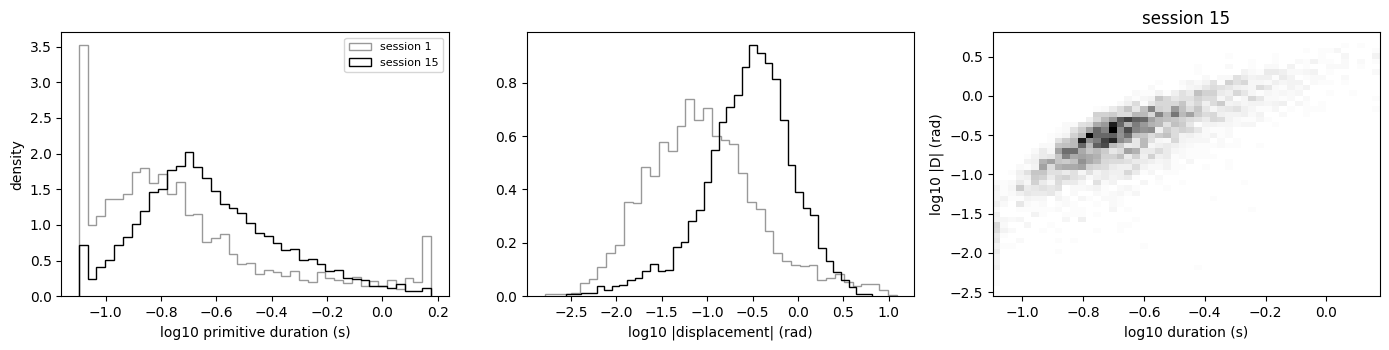

In [8]:
P = []
for k, s in S.items():
    for i, (p, r2) in enumerate(FITS[k, 'minjerk']):
        for j, row in enumerate(pr.primitive_table('minjerk', p)):
            P.append(dict(session=k, movement=i, order=j, epoch=s['mv'].epoch[i], **row))
P = pd.DataFrame(P)
P['absD'] = P.D.abs()
P = P[P.absD > 1e-3]     # drop numerically empty primitives
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for k, c in zip(S, [GREY, BLACK]):
    q = P.query('session == @k')
    axs[0].hist(np.log10(q.duration), 40, histtype='step', color=c, density=True, label=f'session {k}')
    axs[1].hist(np.log10(q.absD), 40, histtype='step', color=c, density=True)
axs[0].set(xlabel='log10 primitive duration (s)', ylabel='density'); axs[0].legend(fontsize=8)
axs[1].set(xlabel='log10 |displacement| (rad)')
kl = max(S); q = P.query('session == @kl')
h = axs[2].hist2d(np.log10(q.duration), np.log10(q.absD), 50, cmap='Greys', cmin=1)
axs[2].set(xlabel='log10 duration (s)', ylabel='log10 |D| (rad)', title=f'session {kl}')
plt.tight_layout()

## First vs last session: what changes

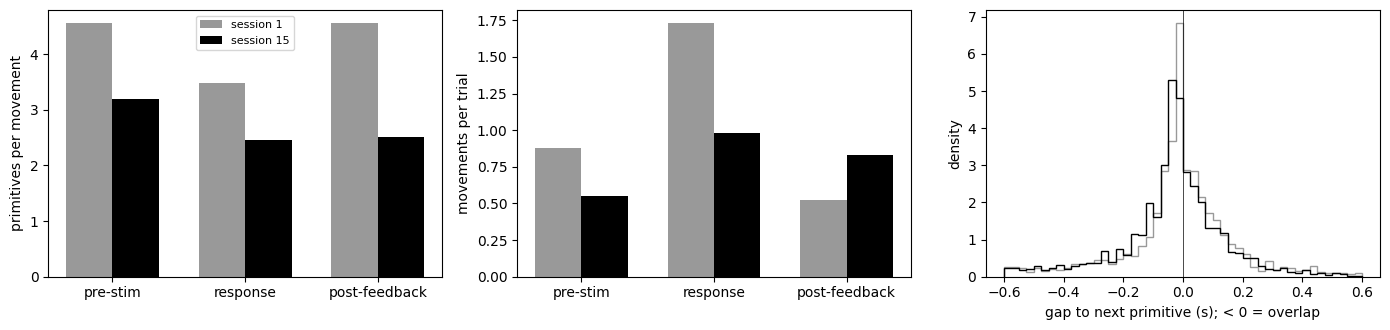

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
w = .35
for j, (k, c) in enumerate(zip(S, [GREY, BLACK])):
    mv = S[k]['mv']
    g = mv.groupby('epoch')
    x = np.arange(len(EPOCHS)) + (j - .5) * w
    axs[0].bar(x, g.n_minjerk.mean().reindex(EPOCHS), w, color=c, label=f'session {k}')
    axs[1].bar(x, (g.size() / len(S[k]['tr'])).reindex(EPOCHS), w, color=c)
    # overlap: gap between a primitive's end and the next one's start, within movements
    q = P.query('session == @k').sort_values(['movement', 'start'])
    nxt = q.groupby('movement').start.shift(-1)
    gap = (nxt - (q.start + q.duration)).dropna()
    axs[2].hist(gap, np.linspace(-.6, .6, 49), histtype='step', color=c, density=True)
for ax in axs[:2]: ax.set_xticks(range(len(EPOCHS)), EPOCHS)
axs[0].set(ylabel='primitives per movement'); axs[0].legend(fontsize=8)
axs[1].set(ylabel='movements per trial')
axs[2].axvline(0, c='k', lw=.5); axs[2].set(xlabel='gap to next primitive (s); < 0 = overlap', ylabel='density')
plt.tight_layout()

In [10]:
# toward / away from the final choice, response epoch only (sign convention from the crosstab above)
rows = []
for k, s in S.items():
    resp = s['mv'].query('epoch == "response"')
    sgn = np.sign(resp.groupby('trial').last().displacement)
    ch = s['tr'].choice.values[sgn.index]
    flip = 1 if np.mean(sgn.values == ch) > .5 else -1        # map sign(D) onto choice
    q = P.query('session == @k and epoch == "response"').merge(
        resp[['trial']].reset_index().rename(columns={'index': 'movement'}), on='movement')
    q['toward_choice'] = np.sign(q.D) * flip == s['tr'].choice.values[q.trial]
    rows.append(dict(session=k, sign_maps_to_choice=flip, primitives_toward_choice=q.toward_choice.mean(),
                     response_movements_per_trial=len(resp) / resp.trial.nunique(),
                     median_first_primitive_D=q.query('order == 0').absD.median()))
pd.DataFrame(rows).set_index('session').round(3)

,sign_maps_to_choice,primitives_toward_choice,response_movements_per_trial,median_first_primitive_D
session,,,,
1,-1,0.658,1.796,0.091
15,-1,0.637,1.080,0.488


## Part B · more example decompositions

Random movements from CSHL049's first and last training session (same as Part A), drawn per trial epoch; only the shown movements are fitted. Grey = measured velocity, colours = individual primitives, dashed = their sum. Change `SEED` for a new draw.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from one.api import ONE
import wheel_states as ws, primitives as pr

one = ONE(mode='remote')
MOUSE, SEED, N_COL = 'CSHL049', 0, 8
EPOCHS = ['pre-stim', 'response', 'post-feedback']
man = ws.manifest().query('mouse == @MOUSE').sort_values('session_index')
SESS = {int(r.session_index): r.eid for _, r in man.iloc[[0, -1]].iterrows()}

def epoch_of(on, tr):
    i = np.searchsorted(tr.intervals_0.values, on, side='right') - 1
    if i < 0:
        return 'post-feedback'
    r = tr.iloc[i]
    return 'pre-stim' if on < r.stimOn_times else 'response' if on <= r.feedback_times else 'post-feedback'

S = {}
for k, eid in SESS.items():
    dm, tr = ws.load_session(eid, MOUSE)
    mv = pd.DataFrame(one.load_object(eid, 'wheelMoves', collection='alf')['intervals'], columns=['onset', 'offset'])
    mv['epoch'] = [epoch_of(o, tr) for o in mv.onset]
    S[k] = dict(t=dm.times.values, v=dm.velocity.values.astype(float), mv=mv)

def show(k, idx, kind, title):
    s = S[k]; mv = s['mv']
    rows = len(idx)
    fig, axs = plt.subplots(rows, N_COL, figsize=(2.2 * N_COL, 2.1 * rows), squeeze=False)
    for r, (label, ii) in enumerate(idx.items()):
        for c in range(N_COL):
            ax = axs[r, c]
            if c >= len(ii):
                ax.axis('off'); continue
            i = ii[c]
            tt, vv = pr.movement_window(s['t'], s['v'], mv.onset[i], mv.offset[i])
            p, r2 = pr.fit_movement(kind, tt, vv)
            ax.plot(tt, vv, c='0.75', lw=3)
            for comp in pr.components(kind, tt, p): ax.plot(tt, comp, lw=1)
            ax.plot(tt, pr.model(kind, tt, p), c='k', lw=1, ls='--')
            ax.axhline(0, c='k', lw=.3)
            ax.set_title(f'N={len(r2)}, R²={r2[-1]:.2f}, {tt[-1] - tt[0]:.2f} s', fontsize=7)
            ax.tick_params(labelsize=6)
        axs[r, 0].set_ylabel(f'{label}\nvelocity (rad/s)', fontsize=8)
    fig.suptitle(title, y=1.0); plt.tight_layout()

def draw(k, seed=SEED):
    rng = np.random.default_rng(seed); mv = S[k]['mv']
    return {e: rng.choice(mv.index[mv.epoch == e], min(N_COL, (mv.epoch == e).sum()), replace=False) for e in EPOCHS}

### First session — minimum-jerk

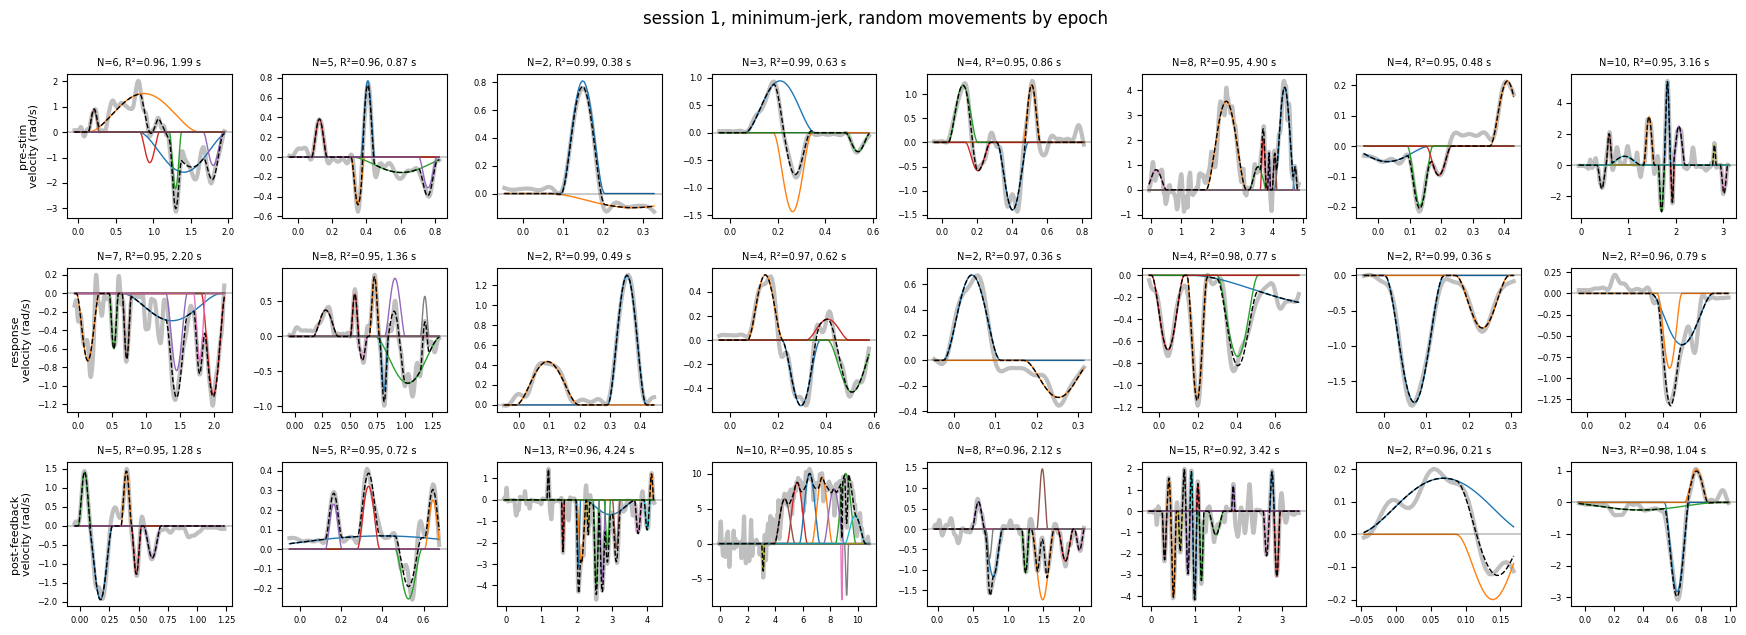

In [2]:
k = min(S); IDX_first = draw(k)
show(k, IDX_first, 'minjerk', f'session {k}, minimum-jerk, random movements by epoch')

### First session — the same movements, lognormal

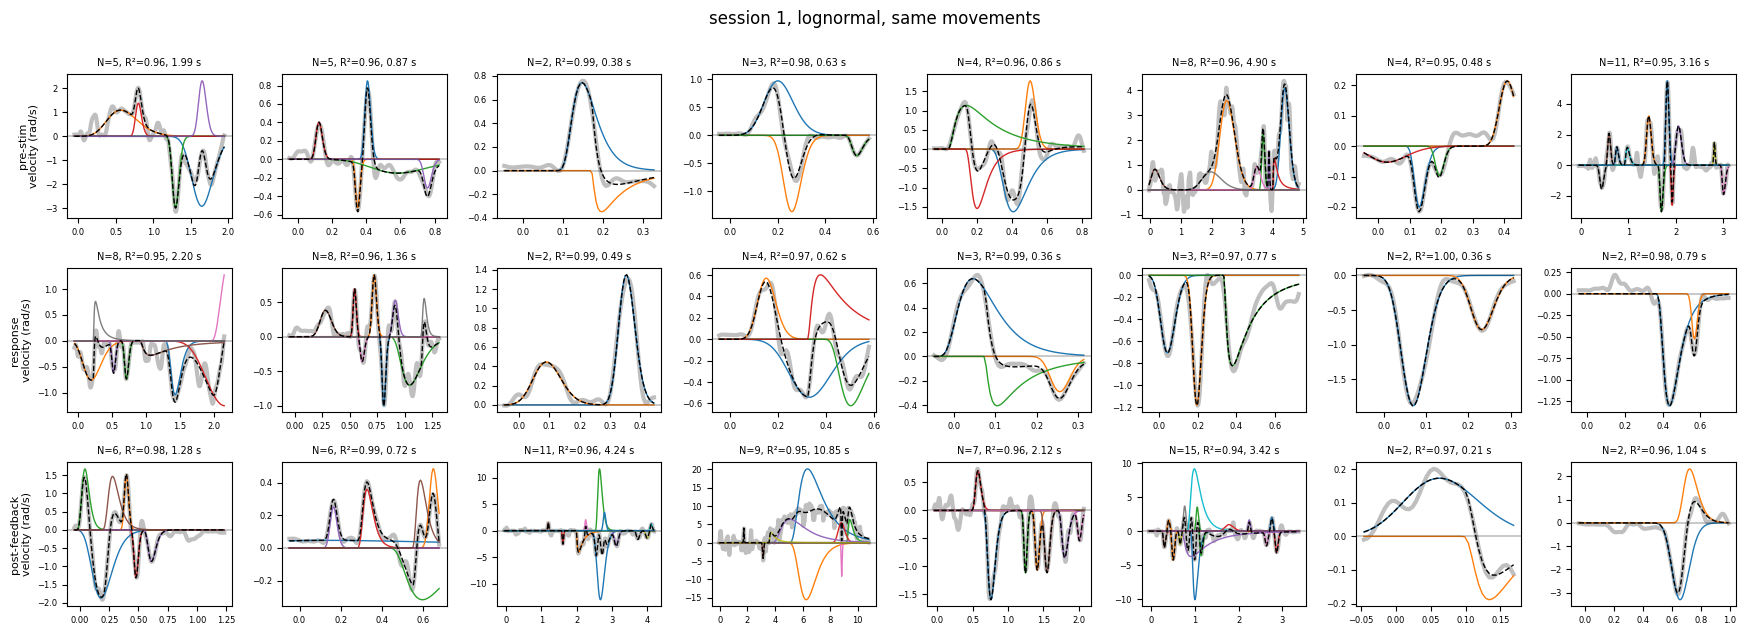

In [3]:
show(k, IDX_first, 'lognormal', f'session {k}, lognormal, same movements')

### Last session — minimum-jerk

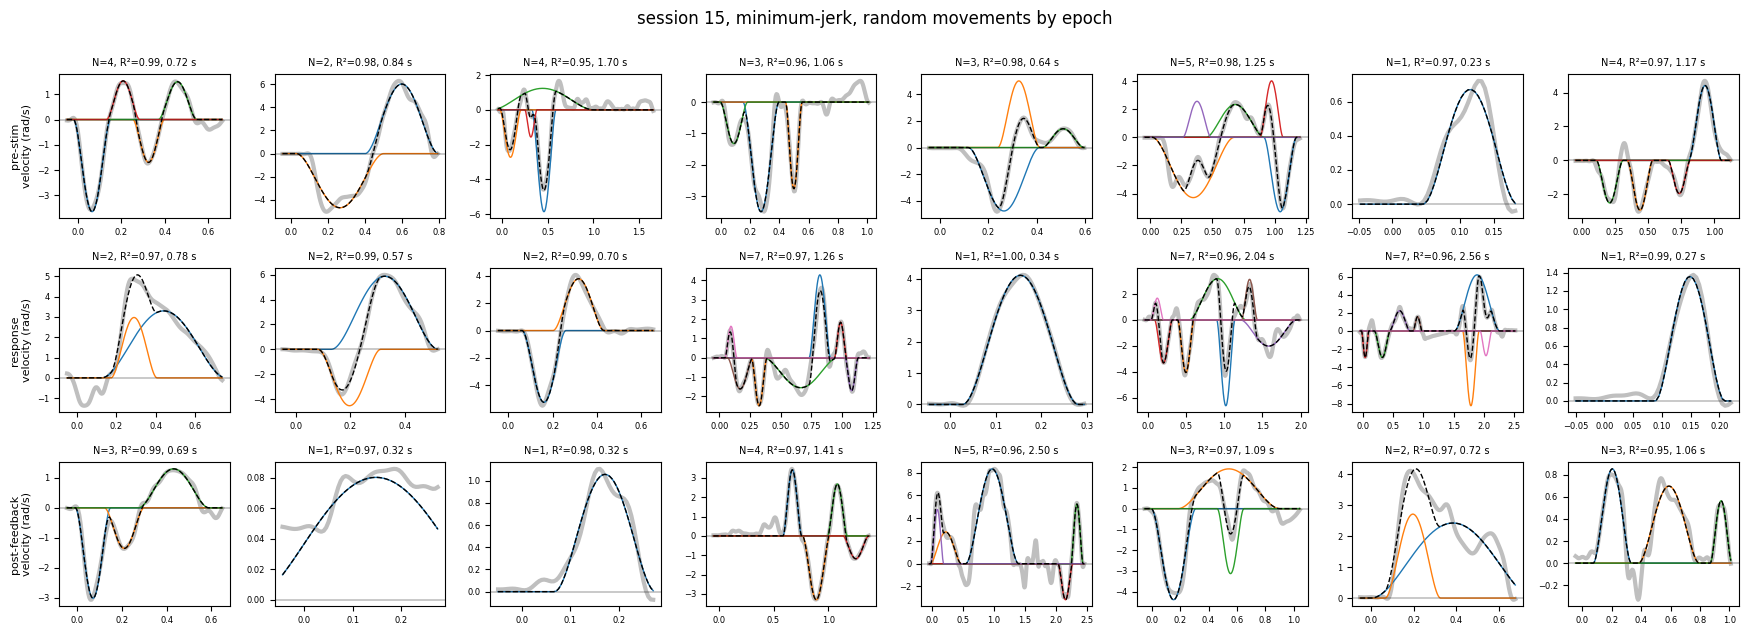

In [4]:
k = max(S); IDX_last = draw(k)
show(k, IDX_last, 'minjerk', f'session {k}, minimum-jerk, random movements by epoch')

### Last session — the same movements, lognormal

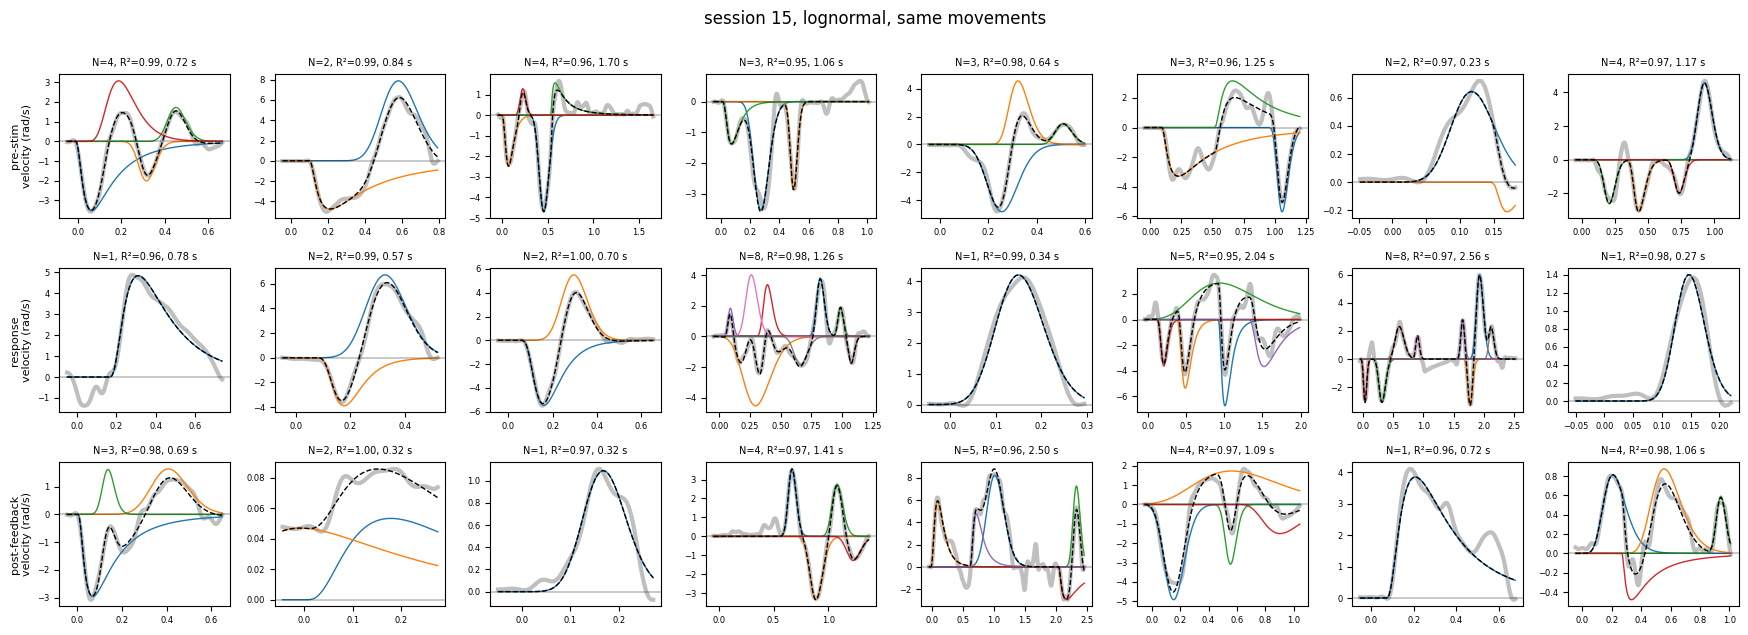

In [5]:
show(k, IDX_last, 'lognormal', f'session {k}, lognormal, same movements')

### Long movements (> 1.5 s), both sessions, minimum-jerk

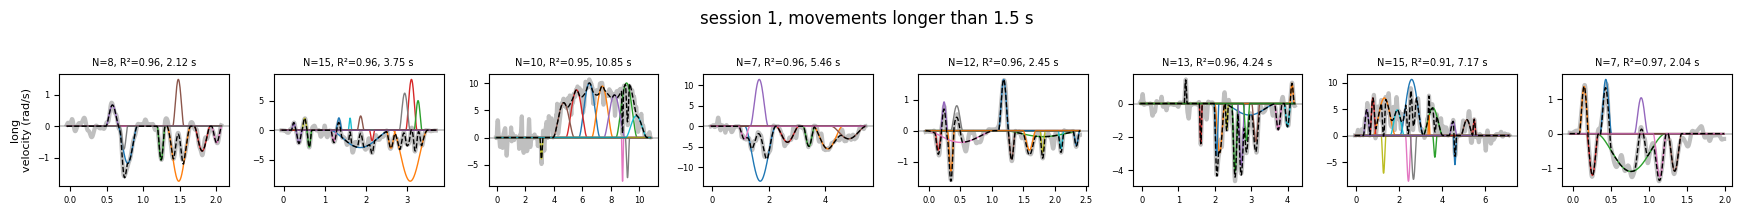

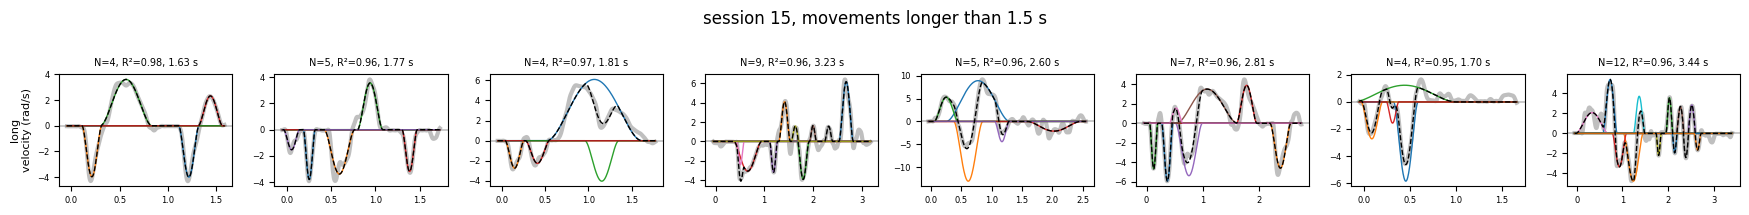

In [6]:
for k in S:
    mv = S[k]['mv']; rng = np.random.default_rng(SEED)
    long_ = mv.index[(mv.offset - mv.onset) > 1.5]
    show(k, {'long': rng.choice(long_, min(N_COL, len(long_)), replace=False)}, 'minjerk', f'session {k}, movements longer than 1.5 s')

### Short movements (< 0.3 s), both sessions, minimum-jerk

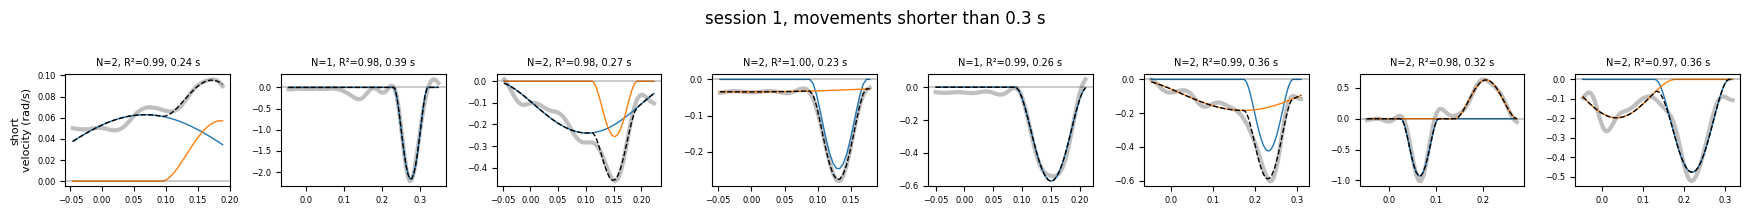

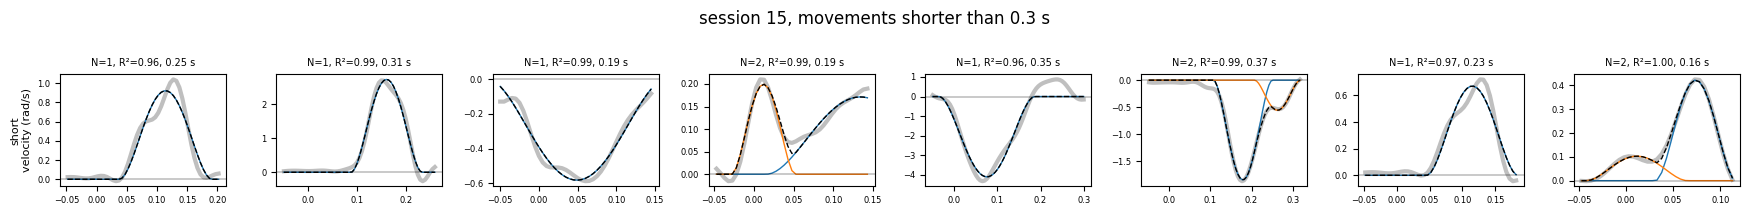

In [7]:
for k in S:
    mv = S[k]['mv']; rng = np.random.default_rng(SEED)
    short = mv.index[(mv.offset - mv.onset) < 0.3]
    show(k, {'short': rng.choice(short, min(N_COL, len(short)), replace=False)}, 'minjerk', f'session {k}, movements shorter than 0.3 s')